# 선형 회귀 (Linear regression)
-y =mx + b 

-ex)무게 =1차길이.x*기울기.m+y절편.b

In [2]:
import matplotlib.pyplot as plt    
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'   
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd                                               
import numpy as np                                         
from sklearn import svm,metrics                            
from sklearn.neighbors import KNeighborsClassifier   #분류
from sklearn.neighbors import KNeighborsRegressor    #예측
from sklearn.linear_model import LinearRegression    #예측
from sklearn.metrics import mean_absolute_error      #평균절대값오차 오차범위     
from sklearn.preprocessing import StandardScaler     #정규화 클래스 
from sklearn.model_selection import train_test_split       

In [3]:
# 데이터전처리
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
#label
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [4]:
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [5]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
test_data[:3]

array([[24. ],
       [35. ],
       [22.7]])

In [6]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_data,train_label)

# 데이터 예측
predict = lr.predict(test_data)
print("무게예측: ",predict)

# 정확도
score = lr.score(train_data,train_label)
score2 = lr.score(test_data,test_label)
print("train정확도 :",score)
print("test정확도 :",score2)

# 기울기,y절편 확인 - LinearRegression() 사용 할 때 나타남.
print('기울기 : ',lr.coef_)
print('y절편 : ',lr.intercept_)

무게예측:  [ 239.05017609  647.03756224  190.833485    164.87065134 -142.97437639
  164.87065134   53.60136421   42.4744355   565.44008501  413.37205926
  261.30403352   90.69112659  201.96041372  361.44639194]
train정확도 : 0.9221222506821036
test정확도 : 0.8304500050020014
기울기 :  [37.08976238]
y절편 :  -651.1041209512852


In [7]:
# KNeighborsRegressor 50 - 1000, 100-1000 
# 50cm 농어 예측 50-1217, 100-3107
predict2 = lr.predict([[100]])
print("예측무게 : ",predict2)


예측무게 :  [3057.87211673]


예측무게,길이 :  [-465.65530907]


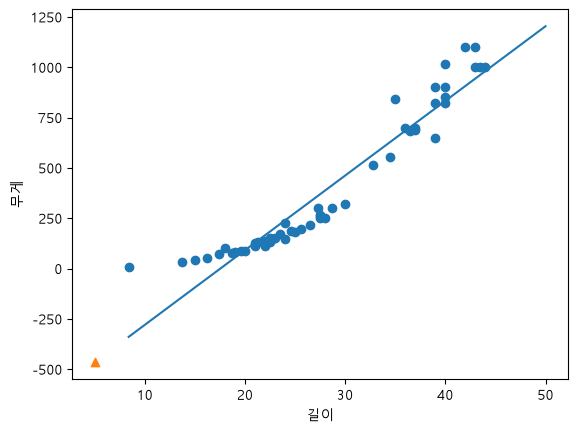

In [11]:
# 길이 입력받아, 무게를 예측하고, 산점도 그래프에 표시하시오.
# 농어길이를 입력하세요.(예:52)
# 예측무게,길이 : 1230,5
# 산점도 그래프에 표시
# 선 그래프도 함께 표시

input1 = input('농어길이를 입력하세여.(예:52,5):')
input1 =float(input1)
predict = lr.predict([[input1]])
print("예측무게,길이 : ", predict)

plt.scatter(perch_length,perch_weight)
plt.scatter(input1,predict,marker="^")

plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_])
plt.xlabel("길이")
plt.ylabel("무게")
plt.show()



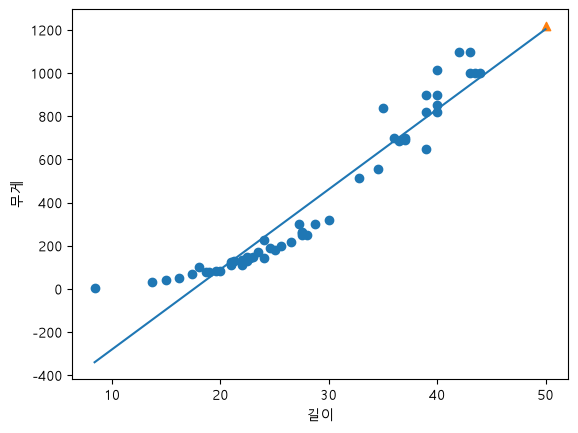

In [9]:
#산점도 그래프
plt.scatter(perch_length,perch_weight)
plt.scatter(50,1217,marker="^")
# plt.scatter(100,3107,marker="D")

plt.plot([8.4,50],[8.4*lr.coef_+lr.intercept_,50*lr.coef_+lr.intercept_]) #선그래프
plt.xlabel("길이")
plt.ylabel("무게")
plt.show()